# 01 — MTJ Stochastic Cortical Spiking Neuron
**Sengupta · Panda · Wijesinghe · Kim · Roy, Scientific Reports 6, 30039 (2016)**

This Colab reconstructs the paper's computational chain:
\[
I_{syn}\rightarrow\text{spin torque + thermal noise}\rightarrow m_x(t)
\rightarrow\text{stochastic MTJ switching}\rightarrow\text{spike}
\rightarrow\text{inhibition/homeostasis/STDP}.
\]

Primary source: https://doi.org/10.1038/srep30039  
A 2017 corrigendum corrects Eq. 2 and should be used for a high-fidelity LLG implementation.


## 1. Physics-to-computation map
The paper models the free-layer unit magnetization with stochastic LLG plus spin-transfer torque:
\[
\dot{\mathbf m}=-\gamma\mathbf m\times\mathbf H_{eff}
+\alpha\mathbf m\times\dot{\mathbf m}+\boldsymbol\tau_{STT}+\boldsymbol\tau_{th}.
\]
For the in-plane-anisotropy device, the in-plane magnetization behaves like a membrane state: pulses integrate, the state leaks after pulses, and P→AP reversal is interpreted as a spike.

For fast Colab execution we use a compact stochastic hazard model:
\[
P_{sw}(t|I)=1-e^{-\Gamma(I)t},\qquad
\Gamma=f_0e^{-\Delta_{eff}(I)}.
\]
This is a behavioral surrogate for the paper's stochastic-LLG transfer function, not a claim that the paper used this exact closed form.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from dataclasses import dataclass
rng=np.random.default_rng(7)
kB=1.380649e-23; T=300.; q=1.602176634e-19
print('T =',T,'K')


T = 300.0 K


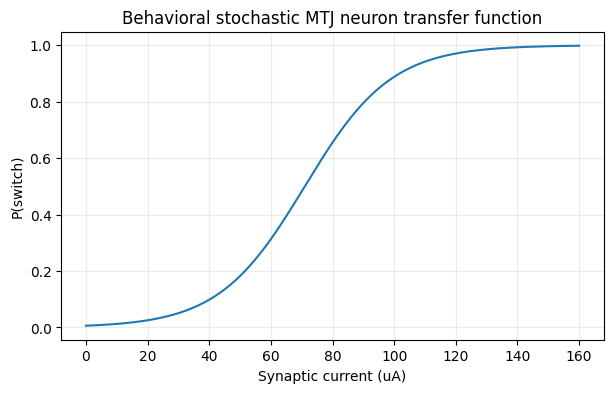

In [2]:
@dataclass
class MTJNeuronParams:
    barrier_kBT: float=20.0
    pulse_ns: float=0.5
    I50_uA: float=71.0
    slope_uA: float=14.0
    reset_current_uA: float=150.0
    read_energy_fJ: float=1.6
    reset_energy_fJ: float=4.5
    write_energy_fJ: float=1.0
p=MTJNeuronParams()

def switching_probability(I_uA,pulse_ns=None,barrier_kBT=None):
    I=np.asarray(I_uA,dtype=float)
    pw=p.pulse_ns if pulse_ns is None else pulse_ns
    Eb=p.barrier_kBT if barrier_kBT is None else barrier_kBT
    I50=p.I50_uA*(Eb/p.barrier_kBT)**0.75*(p.pulse_ns/pw)**0.35
    s=p.slope_uA*np.sqrt(max(pw/p.pulse_ns,1e-9))
    return 1/(1+np.exp(-(I-I50)/s))

I=np.linspace(0,160,500)
plt.figure(figsize=(7,4)); plt.plot(I,switching_probability(I))
plt.xlabel('Synaptic current (uA)'); plt.ylabel('P(switch)')
plt.title('Behavioral stochastic MTJ neuron transfer function'); plt.grid(alpha=.25); plt.show()


## 2. Barrier and pulse-width sweeps
The paper reports representative barriers of 10, 20 and 30 $k_BT$ and pulse widths of 0.2, 0.5 and 1 ns. Increasing barrier shifts switching toward higher current; shorter pulses broaden the stochastic transition.


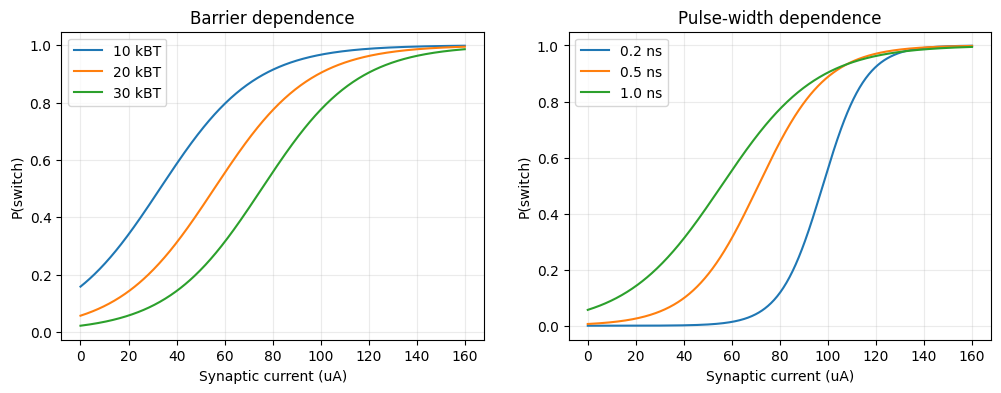

In [3]:
fig,ax=plt.subplots(1,2,figsize=(12,4))
for Eb in [10,20,30]: ax[0].plot(I,switching_probability(I,1.0,Eb),label=f'{Eb} kBT')
ax[0].set(xlabel='Synaptic current (uA)',ylabel='P(switch)',title='Barrier dependence'); ax[0].legend(); ax[0].grid(alpha=.25)
for pw in [.2,.5,1.0]: ax[1].plot(I,switching_probability(I,pw,20),label=f'{pw} ns')
ax[1].set(xlabel='Synaptic current (uA)',ylabel='P(switch)',title='Pulse-width dependence'); ax[1].legend(); ax[1].grid(alpha=.25)
plt.show()


## 3. Three-terminal equivalent circuit
The proposed heavy-metal-assisted MTJ separates write/read paths. Synaptic current flows through the heavy metal; the free layer is switched by the generated spin current. A small read current detects P/AP state and a reset current returns AP→P.

```text
crossbar -- I_SYN --> HM/SOT --> free layer
                         │
MTJ read --> detector/inverter --> SPIKE
                         ▲
                       RESET
```


In [4]:
@dataclass
class MTJReadout:
    R_P_ohm: float=1000.
    R_AP_ohm: float=2000.
    V_read: float=.05
    def voltage(self,state):
        R=self.R_P_ohm if state=='P' else self.R_AP_ohm
        return self.V_read*R/(R+self.R_P_ohm)
r=MTJReadout()
for s in ['P','AP']: print(s,r.voltage(s),'V')


P 0.025 V
AP 0.03333333333333333 V


## 4. Time-domain stochastic neuron
Each write interval samples
\[
s_t\sim Bernoulli(P_{sw}(I_t)).
\]
A successful switch produces a spike and invokes reset/refractory time.


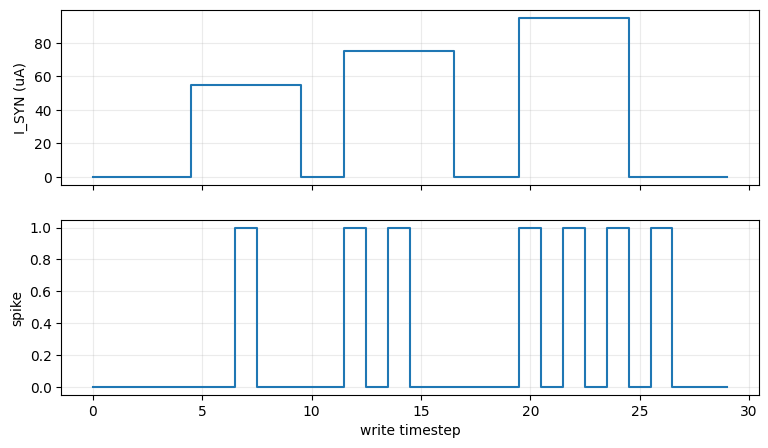

In [5]:
def simulate_stochastic_neuron(I_t_uA,seed=1,reset_steps=1):
    rr=np.random.default_rng(seed); probs=switching_probability(I_t_uA)
    spikes=np.zeros(len(probs),dtype=int); refractory=0
    for t,prob in enumerate(probs):
        if refractory: refractory-=1; continue
        if rr.random()<prob: spikes[t]=1; refractory=reset_steps
    return spikes,probs
I_t=np.zeros(30); I_t[5:10]=55; I_t[12:17]=75; I_t[20:25]=95
spikes,probs=simulate_stochastic_neuron(I_t,3)
fig,ax=plt.subplots(2,1,figsize=(9,5),sharex=True)
ax[0].step(range(len(I_t)),I_t,where='mid'); ax[0].set_ylabel('I_SYN (uA)'); ax[0].grid(alpha=.25)
ax[1].step(range(len(spikes)),spikes,where='mid'); ax[1].set_ylabel('spike'); ax[1].set_xlabel('write timestep'); ax[1].grid(alpha=.25)
plt.show()


## 5. Monte-Carlo stochasticity
Repeated presentations of the same current should reproduce the transfer probability statistically.


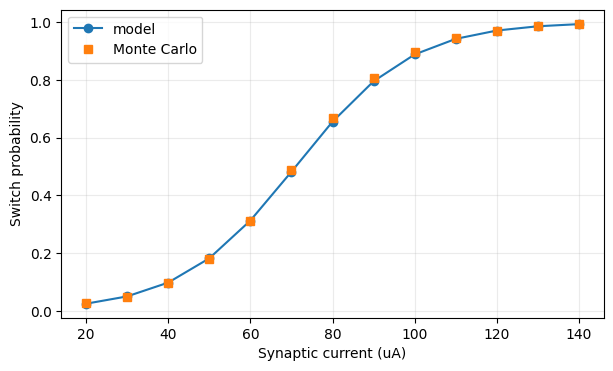

max abs MC error = 0.012105055271962484


In [6]:
def empirical_probability(I_uA,trials=5000,seed=123):
    rr=np.random.default_rng(seed); prob=switching_probability(I_uA)
    return np.mean(rr.random(trials)<prob)
currents=np.arange(20,141,10)
emp=np.array([empirical_probability(x) for x in currents]); theory=switching_probability(currents)
plt.figure(figsize=(7,4)); plt.plot(currents,theory,'o-',label='model'); plt.plot(currents,emp,'s',label='Monte Carlo')
plt.xlabel('Synaptic current (uA)'); plt.ylabel('Switch probability'); plt.legend(); plt.grid(alpha=.25); plt.show()
print('max abs MC error =',np.max(np.abs(emp-theory)))


## 6. Crossbar equation
The paper interfaces stochastic MTJ neurons to programmable resistive crossbars:
\[
I_j(t)=\sum_i G_{ij}V_i(t).
\]
The network study uses 4-bit synapses and a maximum/minimum resistance ratio of 20. MNIST pixels are rate encoded as input spikes.


In [7]:
def quantize_weight(w,bits=4):
    return np.round(w*(2**bits-1))/(2**bits-1)
def crossbar_current(x,W,Vspike=1.0): return Vspike*(W.T@x)
W=quantize_weight(rng.random((16,9)),4); x=(rng.random(16)<.2).astype(float)
print('Crossbar output:',np.round(crossbar_current(x,W),3))


Crossbar output: [1.067 2.    0.733 0.667 1.467 0.8   0.667 0.933 1.333]


## 7. Lateral inhibition + homeostasis
The paper uses common lateral inhibition so that a firing excitatory neuron suppresses its competitors. Homeostasis progressively scales inputs to prevent one neuron from dominating. The exact network equations should be reconstructed from the paper's cited learning framework; below is a compact runnable surrogate.


In [8]:
def poisson_rate_encode(x,steps=100,rng=None):
    rr=np.random.default_rng() if rng is None else rng
    return (rr.random((steps,len(x)))<np.asarray(x)[None,:]).astype(np.int8)
def winner_take_all(spikes,inhibition_steps=2):
    T,N=spikes.shape; out=np.zeros_like(spikes); inhibit=0
    for t in range(T):
        if inhibit: inhibit-=1; continue
        w=np.flatnonzero(spikes[t])
        if len(w): out[t,w[0]]=1; inhibit=inhibition_steps
    return out
img=np.zeros((28,28)); img[5:23,13:16]=1; img[5:8,10:19]=1
spike_train=poisson_rate_encode(img.ravel(),100,rng)
print('synthetic input spikes:',spike_train.sum())


synthetic input spikes: 7200


## 8. STDP
A standard pair-based form is
\[
\Delta w=
\begin{cases}
A_+e^{-\Delta t/\tau_+},&\Delta t>0,\\
-A_-e^{\Delta t/\tau_-},&\Delta t<0.
\end{cases}
\]
This notebook uses it as a learning kernel; the paper's network couples STDP with stochastic neurons, lateral inhibition and homeostasis.


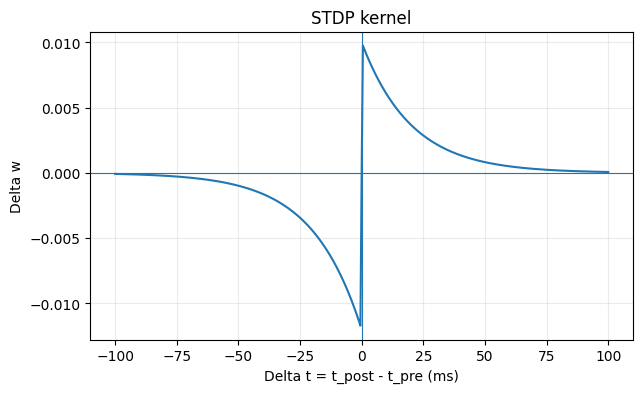

In [9]:
def stdp_delta(dt_ms,A_plus=.01,A_minus=.012,tau_plus=20.,tau_minus=20.):
    dt=np.asarray(dt_ms,float)
    return np.where(dt>0,A_plus*np.exp(-dt/tau_plus),np.where(dt<0,-A_minus*np.exp(dt/tau_minus),0.))
dt=np.linspace(-100,100,401)
plt.figure(figsize=(7,4)); plt.plot(dt,stdp_delta(dt)); plt.axhline(0,linewidth=.8); plt.axvline(0,linewidth=.8)
plt.xlabel('Delta t = t_post - t_pre (ms)'); plt.ylabel('Delta w'); plt.title('STDP kernel'); plt.grid(alpha=.25); plt.show()


## 9. Minimal stochastic SNN scaffold
The published network uses 784 inputs and nine excitatory neurons for MNIST 0/1 recognition. This cell uses synthetic two-class rate patterns to keep the notebook self-contained and fast. It preserves the topology: crossbar → stochastic neurons → competition → plastic weights.


In [10]:
def train_snn(n_in=64,n_neurons=9,steps=80,epochs=8,seed=10):
    rr=np.random.default_rng(seed); A=np.r_[np.full(n_in//2,.75),np.full(n_in-n_in//2,.10)]
    B=np.r_[np.full(n_in//2,.10),np.full(n_in-n_in//2,.75)]
    W=rr.uniform(.15,.65,(n_in,n_neurons)); homeo=np.ones(n_neurons); counts=np.zeros(n_neurons)
    for ep in range(epochs):
        for pat in [A,B]:
            x=poisson_rate_encode(pat,steps,rr)
            raw=np.zeros((steps,n_neurons),int)
            for t in range(steps):
                cur=x[t]@W; cur=cur/np.maximum(homeo,1e-9)
                prob=switching_probability(30+80*cur/np.maximum(cur.max(),1e-9))
                raw[t]=(rr.random(n_neurons)<prob)
            spk=winner_take_all(raw,2); counts+=spk.sum(0)
            for t in np.flatnonzero(np.any(spk,axis=1)):
                w=np.flatnonzero(spk[t])[0]; recent=x[max(0,t-5):t].sum(0)
                W[:,w]+=0.002*recent-0.0005*(recent==0)
            W=np.clip(W,.02,.98)
        rate=counts/(2*(ep+1)); homeo*=np.exp(.03*(rate-2.0)); homeo=np.clip(homeo,.5,5.)
    return W,homeo,counts
W_learned,homeo,counts=train_snn()
print('weight range:',W_learned.min(),W_learned.max())
print('spike counts:',counts.astype(int))


weight range: 0.15024735605550824 0.98
spike counts: [172 192  68   0   0   0   0   0   0]


## 10. Energy model
The paper reports approximately 1 fJ write energy per neuron per time step near the 50% switching current, 1.6 fJ read energy per time step, and 4.5 fJ reset energy per spike. These are architecture-specific reported estimates.
\[
E_{step}=E_{write}+E_{read}+sE_{reset}.
\]


In [11]:
def energy_step(spike): return p.write_energy_fJ+p.read_energy_fJ+spike*p.reset_energy_fJ
for s in [0,1]: print('spike=',s,'E_step=',energy_step(s),'fJ')


spike= 0 E_step= 2.6 fJ
spike= 1 E_step= 7.1 fJ


## 11. High-fidelity upgrade path
1. Implement stochastic LLG with thermal field.
2. Reproduce the corrected 2017 Eq. 2 rather than the erroneous original transcription.
3. Sweep current, pulse width, barrier, temperature.
4. Extract \(P_{sw}(I,t,E_B,T)\).
5. Fit a compact Verilog-A/PySpice model.
6. Connect to ngspice and a crossbar.
7. Connect the extracted device model to a PyTorch SNN.
8. Reproduce the MNIST 0/1 experiment and compare spike statistics and energy.

Open-source stack for later notebooks: **MuMax3/OOMMF/Ubermag → PySpice/ngspice → PyTorch/SNN**.


## Sources
- Sengupta et al., *Magnetic Tunnel Junction Mimics Stochastic Cortical Spiking Neurons*, Scientific Reports 6, 30039 (2016).
- Corrigendum, Scientific Reports 7, 46894 (2017).
- Srinivasan, Sengupta & Roy, *Magnetic Tunnel Junction Based Long-Term Short-Term Stochastic Synapse...*, Scientific Reports 6, 29545 (2016).
- Sengupta, Banerjee & Roy, *Hybrid Spintronic-CMOS Spiking Neural Network with On-Chip Learning*, Physical Review Applied 6, 064003 (2016).
